# 6. STEP 5 – Baseline 모델 구축
## STEP 4 이상치 심화전처리 완성본 연계 · 실제 실행 결과

**기준:** `STEP4_강판결함_이상치_심화전처리_완성(1).ipynb`  
**목표:** 1,941건·27개 입력을 유지한 상태에서 **기본 표준화 / 강건 표준화 / 4개 변수 로그+표준화 × 고정 모델 4종**을 공정하게 비교하고, 다음 실험의 기준선을 확정합니다.

- 주 평가지표: **Validation Macro F1**. 보조: Accuracy, Balanced Accuracy, Weighted F1, 유형별 Recall, 혼동행렬.
- 고정 분할: Train 1,358 / Valid 291 / Test 292, seed=42, 계층 추출.
- 실제 삭제·클리핑·임의 수정·특성 선택·클래스 가중치·SMOTE·하이퍼파라미터 탐색 없음.
- 본 노트북에는 실제 실행한 출력이 저장되어 있습니다. ZIP 전체를 풀고 이 노트북을 실행하는 것을 권장합니다.

> **Test 해석:** 이 분할의 Test 성능은 이전 작업에서 이미 공개되었습니다. 이번에는 전처리·모델 선택을 Valid에서 끝내고 선정 모델만 Test에서 참고 평가합니다. 새로운 독립 검증이나 82% 이상 성능을 보장하는 결과로 해석하지 않습니다.

## 0. 실행 안내와 사전 확정한 실험 규칙

`pip install -r requirements.txt` 후 Python 3.12 환경에서 위에서부터 실행합니다. 아래 셀은 프로젝트 폴더를 찾습니다. STEP 4 출력이 없으면 원본 노트북의 코드를 추출해 재생성하므로 별도 수작업 전처리는 필요하지 않습니다. 첨부 원본 노트북은 `reference/`에 보존했습니다.

1. 전처리·자료 무결성과 원본 hash 확인.
2. Train 내부 동일 5-fold에서 12개 조건 진단. 전처리는 **fold 학습 데이터마다 새로 적합**.
3. 전체 Train으로 모델을 학습한 뒤 Valid 비교. **Valid Macro F1 → Balanced Accuracy → 기본 standard 우선 → 모델명** 순으로 선택.
4. 선택 기록을 저장한 뒤 민감도·변수 중요도 진단, 선정 모델의 기존 Test 참고 평가.
5. Train+Valid로 재학습하지 않고 Train 기준선을 보존. 모델·표·실행 보고서 저장.

Macro F1은 7개 클래스의 F1을 같은 비중으로 평균합니다. Balanced Accuracy는 7개 Recall의 평균입니다. 다수 클래스 비중에 영향을 받는 Accuracy와 함께 해석합니다.

In [1]:
"""STEP 5 baseline: exact STEP 4 reproduction, 3 lossless transforms x 4 fixed models.
Run: python baseline_step5_advanced.py
Selection uses Valid macro F1. Historical Test is a reference evaluation only.
"""
from __future__ import annotations
from pathlib import Path
from copy import deepcopy
from time import perf_counter
from datetime import datetime, timezone
import json
import hashlib
import platform
import subprocess
import sys
import warnings
import base64
import html

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, make_scorer)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits


from IPython.display import display, Image, HTML
candidates=[Path.cwd(),Path.cwd()/'steel_fault_step5_advanced',Path.cwd().parent/'steel_fault_step5_advanced']
ROOT=next((p.resolve() for p in candidates if (p/'reference'/'STEP4_강판결함_이상치_심화전처리_완성(1).ipynb').is_file()),None)
if ROOT is None:
    raise FileNotFoundError('전체 ZIP을 해제한 프로젝트 폴더에서 실행하세요.')
PREP = ROOT / 'outputs_preprocessing'
OUT = ROOT / 'outputs_baseline'
SEED = 42
LABELS = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
STRATEGIES = ['standard', 'robust', 'log1p_standard']
BINARY = ['TypeOfSteel_A300', 'TypeOfSteel_A400']
LOG_FEATURES = ['Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity']
SOURCE_NOTEBOOK = 'STEP4_강판결함_이상치_심화전처리_완성(1).ipynb'


pd.set_option('display.max_columns',30)
pd.set_option('display.width',160)
print('Project:',ROOT)
print('Versions:',{'Python':platform.python_version(),'pandas':pd.__version__,'NumPy':np.__version__,'scikit-learn':sklearn.__version__})

Project: C:\Users\sgr10\Desktop\steel_fault_project\steel_fault_step5_advanced
Versions: {'Python': '3.14.4', 'pandas': '3.0.6', 'NumPy': '2.5.4', 'scikit-learn': '1.9.1'}


In [2]:
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str)+'\n', encoding='utf-8')


def save_csv(frame, filename, index=False):
    OUT.mkdir(exist_ok=True)
    frame.to_csv(OUT / filename, index=index, encoding='utf-8-sig')


def extract_step4():
    """Preserve attachment; adapt working directory and hoist future import for .py only."""
    path = ROOT / 'reference' / SOURCE_NOTEBOOK
    nb = json.loads(path.read_text(encoding='utf-8'))
    chunks = ['from __future__ import annotations\n']
    for i, cell in enumerate(nb['cells']):
        if cell['cell_type'] != 'code':
            continue
        text = ''.join(cell['source']).replace('from __future__ import annotations', '')
        text = text.replace('DATA_DIR = Path.cwd()', 'DATA_DIR = Path(__file__).resolve().parent')
        chunks.append(f'\n# Original source notebook code cell {i}\n'+text)
    target = ROOT / 'step4_preparation.py'
    target.write_text('\n'.join(chunks), encoding='utf-8')
    return target


def ensure_step4(force=False):
    need = [PREP / 'preprocessing_manifest.json', PREP / 'preprocessor.joblib']
    for s in ['train', 'valid', 'test']:
        need.append(PREP / f'{s}_preprocessed.csv')
        for k in ['robust', 'log1p_standard']:
            need.append(PREP / 'outliers_advanced' / f'{s}_variant_{k}.csv')
    if force or not all(p.is_file() for p in need):
        target = extract_step4()
        with (ROOT / 'step4_execution.log').open('w', encoding='utf-8') as log:
            subprocess.run([sys.executable, str(target)], cwd=ROOT, stdout=log,
                           stderr=subprocess.STDOUT, check=True)

## 1. STEP 4 재현과 세 전처리 입력의 정확한 대조

원본 NNA를 읽어 **동일 seed와 분할 순서**로 행을 재현합니다. 원본의 정답 one-hot 7열은 `Fault`로만 합치며 모델 입력에 포함하지 않습니다.

CSV는 반올림 없이 다시 읽도록 `float_precision="round_trip"`을 사용합니다. 저장된 9개 행렬(세 전처리 × 세 분할)이 해당 Train 적합 변환기의 출력과 정확히 같은지 확인합니다. 중앙값·평균·분산·IQR도 원시 Train에서 다시 계산해 학습 범위를 확인합니다.

In [3]:
def verify_scaler_fit(prep, raw_train):
    """Check median and actual scaler statistics, not just output shape."""
    for _, transformer, cols in prep.transformers_:
        if not isinstance(transformer, Pipeline):
            continue
        x = raw_train[cols]
        imputer = next(v for _, v in transformer.steps if hasattr(v, 'statistics_'))
        expected = x.median() if imputer.strategy == 'median' else x.mode().iloc[0]
        np.testing.assert_allclose(imputer.statistics_, expected, rtol=0, atol=1e-12)
        a = imputer.transform(x)
        for name, step in transformer.steps[1:]:
            if hasattr(step, 'mean_'):
                np.testing.assert_allclose(step.mean_, np.mean(a, axis=0), rtol=0, atol=1e-9)
                np.testing.assert_allclose(step.var_, np.var(a, axis=0), rtol=1e-12, atol=1e-9)
                assert int(step.n_samples_seen_) == len(x)
            elif hasattr(step, 'center_'):
                np.testing.assert_allclose(step.center_, np.median(a, axis=0), rtol=0, atol=1e-12)
                iqr = np.percentile(a, 75, axis=0)-np.percentile(a, 25, axis=0)
                iqr[iqr < 10*np.finfo(iqr.dtype).eps] = 1
                np.testing.assert_allclose(step.scale_, iqr, rtol=0, atol=1e-12)
            a = step.transform(a)


def load_verify():
    ensure_step4()
    OUT.mkdir(exist_ok=True)
    manifest = json.loads((PREP/'preprocessing_manifest.json').read_text())
    names = [x.strip() for x in (ROOT/'Faults27x7_var').read_text(encoding='utf-8-sig').splitlines() if x.strip()]
    raw = pd.read_csv(ROOT/'Faults.NNA', sep=r'\s+', header=None, names=names)
    assert raw.shape == (1941, 34)
    assert raw[LABELS].isin([0,1]).all().all() and raw[LABELS].sum(axis=1).eq(1).all()
    raw['Fault'] = raw[LABELS].idxmax(axis=1)
    features = manifest['features_original']
    assert len(features) == 27 and not raw.duplicated(features).any()
    assert manifest['source_sha256'] == digest(ROOT/manifest['source'])
    tv, te = train_test_split(raw, test_size=.15, stratify=raw.Fault, random_state=SEED)
    tr, va = train_test_split(tv, test_size=.15/.85, stratify=tv.Fault, random_state=SEED)
    parts = {k:{'raw':p[features].copy(), 'y':p.Fault.copy(), 'X':{}} for k,p in [('train',tr),('valid',va),('test',te)]}
    assignment = pd.read_csv(PREP/'10_split_assignment_audit.csv')
    assert len(assignment) == 1941 and assignment.original_index.is_unique
    preprocessors = {'standard':joblib.load(PREP/'preprocessor.joblib')}
    for key in STRATEGIES[1:]:
        preprocessors[key] = joblib.load(PREP/'outliers_advanced'/f'outlier_variant_{key}_train_fitted.joblib')
    checks = []
    for key, prep in preprocessors.items():
        assert set(prep.get_feature_names_out()) == set(features)
        verify_scaler_fit(prep, parts['train']['raw'])
        for split, part in parts.items():
            path = (PREP/f'{split}_preprocessed.csv' if key == 'standard' else
                    PREP/'outliers_advanced'/f'{split}_variant_{key}.csv')
            saved = pd.read_csv(path, float_precision='round_trip')
            assert saved.columns.tolist() == features + ['Fault']
            assert saved.Fault.tolist() == part['y'].tolist()
            x = pd.DataFrame(prep.transform(part['raw']), index=part['raw'].index,
                             columns=prep.get_feature_names_out())[features]
            np.testing.assert_array_equal(saved.drop(columns='Fault').to_numpy(), x.to_numpy())
            assert np.isfinite(x.to_numpy()).all()
            np.testing.assert_array_equal(x[BINARY], part['raw'][BINARY])
            assert set(assignment.loc[assignment.split.str.lower().eq(split), 'original_index']) == set(x.index)
            part['X'][key] = x
            checks.append({'strategy':key,'split':split,'rows':len(x),'features':len(features),
                'exact_csv_transform_match':True,'binary_preserved':True,'fit_statistics_train_only':True,
                'deleted_rows':0,'missing':int(x.isna().sum().sum())})
    indexes = [set(p['raw'].index) for p in parts.values()]
    assert len(set.union(*indexes)) == 1941 and all(not indexes[a]&indexes[b] for a,b in [(0,1),(0,2),(1,2)])
    hashes = [set(pd.util.hash_pandas_object(p['raw'], index=False)) for p in parts.values()]
    assert all(not hashes[a]&hashes[b] for a,b in [(0,1),(0,2),(1,2)])
    advanced = manifest['advanced_outliers']
    assert advanced['actual_rows_deleted'] == 0 and advanced['actual_values_overwritten'] == 0
    assert sorted(advanced['physical_suspect_rows']) == [519,592]
    suspects = pd.read_csv(PREP/'outliers_advanced'/'02_luminosity_consistency_review.csv')
    lookup = {int(i)+1:s for s,p in parts.items() for i in p['raw'].index}
    suspects['split'] = suspects.row_1based.map(lookup)
    counts = pd.DataFrame({k:p['y'].value_counts().reindex(LABELS) for k,p in parts.items()}).rename_axis('class')
    save_csv(pd.DataFrame(checks), '00_preprocessing_verification.csv')
    save_csv(counts.reset_index(), '01_class_counts.csv')
    save_csv(suspects, '02_source_consistency_review.csv')
    fingerprints = {str(p.relative_to(ROOT)):digest(p) for p in [ROOT/'Faults.NNA', ROOT/'Faults27x7_var', ROOT/'reference'/SOURCE_NOTEBOOK]}
    write_json(OUT/'source_fingerprints.json', fingerprints)
    return {'raw':raw, 'parts':parts, 'features':features,'preprocessors':preprocessors,
            'manifest':manifest,'checks':pd.DataFrame(checks),'counts':counts,'suspects':suspects,'fingerprints':fingerprints}

In [4]:
data=load_verify()
display(data['checks'])
display(data['counts'])
print('원본·입력 정렬·27개 열·1,941행·이진값 보존·Train 적합 통계 검증 통과')

c:\Users\sgr10\.venv314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\sgr10\.venv314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\sgr10\.venv314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.8.0 when using version 1.9.1. This might lead to breaking code or i

,strategy,split,rows,features,exact_csv_transform_match,binary_preserved,fit_statistics_train_only,deleted_rows,missing
0,standard,train,1358,27,True,True,True,0,0
1,standard,valid,291,27,True,True,True,0,0
2,standard,test,292,27,True,True,True,0,0
3,robust,train,1358,27,True,True,True,0,0
4,robust,valid,291,27,True,True,True,0,0
5,robust,test,292,27,True,True,True,0,0
6,log1p_standard,train,1358,27,True,True,True,0,0
7,log1p_standard,valid,291,27,True,True,True,0,0
8,log1p_standard,test,292,27,True,True,True,0,0


,train,valid,test
class,,,
Pastry,110,24,24
Z_Scratch,133,28,29
K_Scatch,273,59,59
Stains,50,11,11
Dirtiness,39,8,8
Bumps,282,60,60
Other_Faults,471,101,101


원본·입력 정렬·27개 열·1,941행·이진값 보존·Train 적합 통계 검증 통과


## 2. 이상치 심화전처리 정책의 적용

| 전략 | 연속형 25열 처리 | 강종 2열 |
|---|---|---|
| standard | 중앙값 대체 → StandardScaler | 0/1 유지 |
| robust | 중앙값 대체 → RobustScaler(25%, 75%) | 0/1 유지 |
| log1p_standard | 면적·X둘레·Y둘레·밝기합 4열은 중앙값 대체 → log1p → StandardScaler. 나머지 21열은 중앙값 대체 → StandardScaler | 0/1 유지 |

`StandardScaler=(x−mean)/std`, `RobustScaler=(x−median)/IQR`, `log1p=log(1+x)`입니다. 기준 통계는 Train에서만 학습합니다. `LogOfAreas` 등 이미 로그로 파생된 변수는 재로그하지 않습니다. 결측치는 실제로 없지만 새 입력에 대응하도록 STEP 4의 대체 단계를 유지했습니다.

Train 면적 IQR 279건을 일괄 삭제하면 K_Scatch 273건 중 231건(84.62%)을 잃을 수 있습니다. 이상치 플래그는 검토에 사용하고 모델 입력에 추가하지 않습니다. **519·592행의 밝기 관계 의심은 원자료 확인 전 그대로 유지**합니다.

In [5]:
display(data['suspects'])
outlier_stats=pd.read_csv(PREP/'outliers_advanced'/'03_train_only_iqr_mad_thresholds.csv')
display(outlier_stats.loc[outlier_stats.feature.isin(LOG_FEATURES),['feature','iqr_candidates_train','mad_candidates_train','skewness']])
display(pd.read_csv(PREP/'outliers_advanced'/'14_transformer_variants_quality_audit.csv'))

,row_1based,Pixels_Areas,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,mean_luminosity,min_luminosity_times_area,max_luminosity_times_area,Fault,split
0,519,5357,764,123,134,0.142617,658911,717838,K_Scatch,train
1,592,5993,589956,132,132,98.440848,791076,791076,K_Scatch,train


,feature,iqr_candidates_train,mad_candidates_train,skewness
4,Pixels_Areas,279,352,3.160005
5,X_Perimeter,227,321,2.869364
6,Y_Perimeter,126,300,2.833550
7,Sum_of_Luminosity,281,340,3.289849


,strategy,split,n_rows,n_features,missing_cells,actual_removed,fitted_on
0,robust,train,1358,27,0,0,Train only
1,robust,valid,291,27,0,0,Train only
2,robust,test,292,27,0,0,Train only
3,log1p_standard,train,1358,27,0,0,Train only
4,log1p_standard,valid,291,27,0,0,Train only
5,log1p_standard,test,292,27,0,0,Train only


## 3. 고정 Baseline 모델 4종

| 모델 | 고정 설정 | 확인할 점 |
|---|---|---|
| Dummy | Train 다수 클래스 예측 | 불균형 상태의 최소 기준 |
| LogisticRegression | C=1, lbfgs, 최대 5,000회 | 선형 분류의 한계·전처리 효과 |
| RandomForest | 트리 300개, max_features=sqrt | 비선형 상호작용·과적합 격차 |
| HistGradientBoosting | 100회, 학습률 0.1, 리프 최대 31, 조기종료 해제 | 고정 부스팅 기준선 |

가중치·리샘플링 없이 동일 자료를 사용합니다. 수렴 경고가 발생하면 실행을 중단해 미수렴 모델의 점수를 결과로 인정하지 않습니다.

In [6]:
def model_templates():
    return {
        'Dummy':DummyClassifier(strategy='most_frequent', random_state=SEED),
        'LogisticRegression':LogisticRegression(C=1, solver='lbfgs', max_iter=5000,
            tol=1e-4, class_weight=None, random_state=SEED),
        'RandomForest':RandomForestClassifier(n_estimators=300, max_features='sqrt',
            min_samples_leaf=1, class_weight=None, random_state=SEED, n_jobs=1),
        'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=100, learning_rate=.1,
            max_leaf_nodes=31, early_stopping=False, class_weight=None, random_state=SEED),
    }


def raw_pipeline(prep, features, model, fitted=False):
    transform = deepcopy(prep) if fitted else clone(prep)
    transform.set_output(transform='pandas')
    for _, inner, _ in (transform.transformers_ if fitted else transform.transformers):
        if hasattr(inner, 'set_output'):
            inner.set_output(transform='default')
    reorder = ColumnTransformer([('original_order','passthrough',features)],
        verbose_feature_names_out=False).set_output(transform='pandas')
    if fitted:
        # This passthrough selector learns column metadata only, no statistics.
        # Initialize its schema so the already fitted pipeline can predict.
        reorder.fit(pd.DataFrame(np.zeros((1,len(features))),columns=features))
    return Pipeline([('preprocessor',transform),('order',reorder),('model',model if fitted else clone(model))])


def metrics(y, pred):
    return {'accuracy':accuracy_score(y,pred),
        'macro_f1':f1_score(y,pred,labels=LABELS,average='macro',zero_division=0),
        'balanced_accuracy':balanced_accuracy_score(y,pred),
        'weighted_f1':f1_score(y,pred,labels=LABELS,average='weighted',zero_division=0)}


def fit_checked(estimator, x, y, context):
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(1):
        warnings.simplefilter('always')
        start = perf_counter(); estimator.fit(x,y); elapsed = perf_counter()-start
    if any(issubclass(w.category,ConvergenceWarning) for w in caught):
        raise RuntimeError(f'Convergence failure: {context}')
    return elapsed, [{'context':context,'category':w.category.__name__,'message':str(w.message)} for w in caught]


def class_report(y,pred):
    return pd.DataFrame(classification_report(y,pred,labels=LABELS,zero_division=0,output_dict=True)).T.loc[LABELS].reset_index(names='class')

In [7]:
templates=model_templates()
for name,model in templates.items():
    print(name,':',model)

Dummy : DummyClassifier(random_state=42, strategy='most_frequent')
LogisticRegression : LogisticRegression(C=1, max_iter=5000, random_state=42)
RandomForest : RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=42)
HistGradientBoosting : HistGradientBoostingClassifier(early_stopping=False, random_state=42)


## 4. Train 내부 5-fold 교차검증

원시 Train에서 5개 fold를 만든 뒤 모든 조건에 동일하게 사용합니다. 각 fold의 중앙값·스케일 통계를 다시 학습합니다. 전체 Train에서 이미 전처리한 CSV로 교차검증하면 평가 fold의 정보가 통계에 반영될 수 있으므로 이 단계에서는 원시 입력 Pipeline을 사용합니다.

CV는 안정성 진단이고 최종 선택은 고정 Valid 점수로 수행합니다. CV 평균의 ±SD는 신뢰구간이 아닙니다.

In [8]:
def cross_validate_train(data, templates):
    tr = data['parts']['train']; x,y = tr['raw'],tr['y']
    folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(x,y))
    audits = pd.concat([pd.DataFrame({'original_index':x.index[eval_i],'fold':f})
        for f,(_,eval_i) in enumerate(folds,1)],ignore_index=True)
    save_csv(audits,'03_cv_fold_assignments.csv')
    rows,warn = [],[]
    for key in STRATEGIES:
        for name,template in templates.items():
            for fold,(fit_i,eval_i) in enumerate(folds,1):
                pipe = raw_pipeline(data['preprocessors'][key],data['features'],template)
                elapsed,ww = fit_checked(pipe,x.iloc[fit_i],y.iloc[fit_i],f'CV/{key}/{name}/{fold}'); warn+=ww
                verify_scaler_fit(pipe.named_steps['preprocessor'],x.iloc[fit_i])
                with threadpool_limits(1):pred = pipe.predict(x.iloc[eval_i])
                rows.append({'strategy':key,'model':name,'fold':fold,'fit_rows':len(fit_i),'eval_rows':len(eval_i),
                    **metrics(y.iloc[eval_i],pred),'fit_seconds':elapsed})
            print(f'Train 5-fold finished: {key} / {name}',flush=True)
    detail = pd.DataFrame(rows)
    summary = detail.groupby(['strategy','model'],sort=False).agg(
        cv_macro_f1_mean=('macro_f1','mean'),cv_macro_f1_std=('macro_f1','std'),
        cv_accuracy_mean=('accuracy','mean'),cv_accuracy_std=('accuracy','std')).reset_index()
    save_csv(detail,'04_train_cv_detail.csv');save_csv(summary,'05_train_cv_summary.csv')
    return summary,warn

In [9]:
cv_summary,cv_warnings=cross_validate_train(data,templates)
display(cv_summary.sort_values('cv_macro_f1_mean',ascending=False).round(4))

Train 5-fold finished: standard / Dummy
Train 5-fold finished: standard / LogisticRegression
Train 5-fold finished: standard / RandomForest
Train 5-fold finished: standard / HistGradientBoosting
Train 5-fold finished: robust / Dummy
Train 5-fold finished: robust / LogisticRegression
Train 5-fold finished: robust / RandomForest
Train 5-fold finished: robust / HistGradientBoosting
Train 5-fold finished: log1p_standard / Dummy
Train 5-fold finished: log1p_standard / LogisticRegression
Train 5-fold finished: log1p_standard / RandomForest
Train 5-fold finished: log1p_standard / HistGradientBoosting


,strategy,model,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_accuracy_std
3,standard,HistGradientBoosting,0.8119,0.0279,0.7857,0.0357
7,robust,HistGradientBoosting,0.8119,0.0279,0.7857,0.0357
11,log1p_standard,HistGradientBoosting,0.8119,0.0279,0.7857,0.0357
6,robust,RandomForest,0.7952,0.0225,0.7643,0.0345
2,standard,RandomForest,0.7944,0.0219,0.7628,0.0330
10,log1p_standard,RandomForest,0.7942,0.0234,0.7621,0.0364
9,log1p_standard,LogisticRegression,0.7342,0.0229,0.7172,0.0314
5,robust,LogisticRegression,0.7296,0.0198,0.7135,0.0235
1,standard,LogisticRegression,0.7282,0.0215,0.7091,0.0309
0,standard,Dummy,0.0736,0.0003,0.3468,0.0022


## 5. 동일 Train → Validation 비교 및 선택 고정

모델을 전체 Train으로 학습할 때는 STEP 4에서 저장한 정확한 행렬을 사용하고 재표준화하지 않습니다. 12개 조합의 Train/Valid 격차, Accuracy, Macro F1, Balanced Accuracy와 동일 모델 내 전처리 효과를 저장합니다. 12개 후보 비교에 따른 선택 편향이 있으므로 최고 Valid 점수를 일반화 성능으로 단정하지 않습니다.

In [10]:
def compare_valid(data, templates, cv):
    tr,va = data['parts']['train'],data['parts']['valid']
    rows,reports,fitted,predictions,warn = [],[],{},{},[]
    for key in STRATEGIES:
        for name,template in templates.items():
            identifier = f'{key}__{name}'
            model = clone(template)
            elapsed,ww = fit_checked(model,tr['X'][key],tr['y'],f'Train/{identifier}');warn+=ww
            with threadpool_limits(1):
                pt,pv = model.predict(tr['X'][key]),model.predict(va['X'][key])
            st,sv = metrics(tr['y'],pt),metrics(va['y'],pv)
            rows.append({'candidate':identifier,'strategy':key,'model':name,
                'train_accuracy':st['accuracy'],'train_macro_f1':st['macro_f1'],
                **{'valid_'+k:v for k,v in sv.items()},
                'macro_f1_gap':st['macro_f1']-sv['macro_f1'],'fit_seconds':elapsed})
            report = class_report(va['y'],pv);report.insert(0,'candidate',identifier);reports.append(report)
            save_csv(pd.DataFrame(confusion_matrix(va['y'],pv,labels=LABELS),index=LABELS,columns=LABELS).rename_axis('actual'),
                     f'valid_confusion_{identifier}.csv',index=True)
            fitted[identifier],predictions[identifier] = model,pv
    table = pd.DataFrame(rows).merge(cv,on=['strategy','model'])
    # Ties rounded to 12 decimal places; favor the original standard baseline,
    # then the stable alphabetical model name. No Test metric participates.
    table['_mf1'] = table.valid_macro_f1.round(12)
    table['_ba'] = table.valid_balanced_accuracy.round(12)
    table['_prep_rank'] = table.strategy.map({k:i for i,k in enumerate(STRATEGIES)})
    table = table.sort_values(['_mf1','_ba','_prep_rank','model'],ascending=[False,False,True,True]).drop(
        columns=['_mf1','_ba','_prep_rank']).reset_index(drop=True)
    save_csv(table,'06_validation_comparison.csv')
    save_csv(pd.concat(reports,ignore_index=True),'07_validation_class_metrics.csv')
    save_csv(pd.DataFrame({'original_index':va['raw'].index,'row_1based':va['raw'].index+1,'actual':va['y'].to_numpy(),**predictions}),
        '08_validation_predictions.csv')
    effects=[]
    for name in templates:
        base=table.loc[(table.strategy=='standard')&(table.model==name)].iloc[0]
        pbase=predictions[f'standard__{name}']
        for key in STRATEGIES:
            r=table.loc[(table.strategy==key)&(table.model==name)].iloc[0]
            p=predictions[f'{key}__{name}']; actual=va['y'].to_numpy()
            effects.append({'model':name,'strategy':key,'delta_valid_accuracy':r.valid_accuracy-base.valid_accuracy,
                'delta_valid_macro_f1':r.valid_macro_f1-base.valid_macro_f1,
                'prediction_disagreements_vs_standard':int((p!=pbase).sum()),
                'new_correct':int(((p==actual)&(pbase!=actual)).sum()),
                'new_wrong':int(((p!=actual)&(pbase==actual)).sum())})
    save_csv(pd.DataFrame(effects),'09_preprocessing_effects.csv')
    # Freeze a concrete selection before the only historical Test scoring call.
    selected = table.iloc[0]
    selection = {'selected_candidate':selected.candidate,'selected_strategy':selected.strategy,
        'selected_model':selected.model,'primary_metric':'Valid macro F1',
        'tie_break':'Valid balanced accuracy; standard > robust > log1p_standard; model name',
        'valid_macro_f1':selected.valid_macro_f1,'valid_accuracy':selected.valid_accuracy,
        'fitted_rows':len(tr['y']),'refit_train_valid':False,
        'test_used_in_selection_this_run':False,
        'historical_test_previously_disclosed':True,'test_status':'historical reference; not a fresh independent holdout',
        'timestamp_utc':datetime.now(timezone.utc).isoformat(),
        'models':{k:v.get_params() for k,v in templates.items()}}
    write_json(OUT/'selection_frozen_before_test.json',selection)
    return table,fitted,predictions,pd.DataFrame(effects),warn

In [11]:
comparison,fitted,valid_predictions,effects,fit_warnings=compare_valid(data,templates,cv_summary)
display(comparison[['strategy','model','train_macro_f1','valid_accuracy','valid_macro_f1','valid_balanced_accuracy','cv_macro_f1_mean','cv_macro_f1_std','macro_f1_gap']].round(4))
selected=comparison.iloc[0]
print('선정:',selected.candidate)
print('선정 기록 저장:',(OUT/'selection_frozen_before_test.json').name)

,strategy,model,train_macro_f1,valid_accuracy,valid_macro_f1,valid_balanced_accuracy,cv_macro_f1_mean,cv_macro_f1_std,macro_f1_gap
0,standard,HistGradientBoosting,1.0000,0.7869,0.7619,0.7329,0.8119,0.0279,0.2381
1,robust,HistGradientBoosting,1.0000,0.7869,0.7619,0.7329,0.8119,0.0279,0.2381
2,log1p_standard,HistGradientBoosting,1.0000,0.7869,0.7619,0.7329,0.8119,0.0279,0.2381
3,log1p_standard,RandomForest,1.0000,0.7560,0.7229,0.6852,0.7942,0.0234,0.2771
4,standard,RandomForest,1.0000,0.7526,0.7208,0.6828,0.7944,0.0219,0.2792
5,robust,RandomForest,1.0000,0.7526,0.7208,0.6828,0.7952,0.0225,0.2792
6,robust,LogisticRegression,0.7661,0.6907,0.6543,0.6378,0.7296,0.0198,0.1118
7,log1p_standard,LogisticRegression,0.7741,0.6838,0.6494,0.6340,0.7342,0.0229,0.1247
8,standard,LogisticRegression,0.7654,0.6770,0.6417,0.6302,0.7282,0.0215,0.1237
9,standard,Dummy,0.0736,0.3471,0.0736,0.1429,0.0736,0.0003,-0.0000


선정: standard__HistGradientBoosting
선정 기록 저장: selection_frozen_before_test.json


In [12]:
display(effects.round(5))
selected_valid=class_report(data['parts']['valid']['y'],valid_predictions[selected.candidate])
display(selected_valid.round(4))

,model,strategy,delta_valid_accuracy,delta_valid_macro_f1,prediction_disagreements_vs_standard,new_correct,new_wrong
0,Dummy,standard,0.00000,0.00000,0,0,0
1,Dummy,robust,0.00000,0.00000,0,0,0
2,Dummy,log1p_standard,0.00000,0.00000,0,0,0
3,LogisticRegression,standard,0.00000,0.00000,0,0,0
4,LogisticRegression,robust,0.01375,0.01264,4,4,0
5,LogisticRegression,log1p_standard,0.00687,0.00776,6,3,1
6,RandomForest,standard,0.00000,0.00000,0,0,0
7,RandomForest,robust,0.00000,0.00000,0,0,0
8,RandomForest,log1p_standard,0.00344,0.00203,1,1,0
9,HistGradientBoosting,standard,0.00000,0.00000,0,0,0


,class,precision,recall,f1-score,support
0,Pastry,0.5909,0.5417,0.5652,24.0
1,Z_Scratch,0.9643,0.9643,0.9643,28.0
2,K_Scatch,1.0000,0.9492,0.9739,59.0
3,Stains,1.0000,0.8182,0.9000,11.0
4,Dirtiness,0.7500,0.3750,0.5000,8.0
5,Bumps,0.6364,0.7000,0.6667,60.0
6,Other_Faults,0.7453,0.7822,0.7633,101.0


### 전처리 효과의 해석

`delta_valid_*`는 같은 모델의 standard 대비 비율 차이입니다(0.01=1%p). `new_correct/new_wrong`은 같은 Valid 행에서 예측이 어떻게 바뀌었는지 보여줍니다. 왜도 완화만으로 분류 성능 향상을 주장하지 않습니다. 트리 모델에서도 히스토그램 경계·부동소수점·무작위 분할에 따라 예측이 달라질 수 있어, 작은 차이는 여러 분할과 새 데이터로 확인해야 합니다.

## 6. 선택 후 유사 관측치 민감도와 변수 중요도

STEP 4의 유사 후보는 확정 중복이 아닙니다. Train과 후보 관계가 있는 Valid 행을 제외한 점수는 **선택 후 진단**으로만 보고 선택 규칙에 사용하지 않습니다.

추가 그룹 CV는 Train–Train 후보의 연결 성분을 같은 fold로 묶어 수행합니다. 일반 CV와 fold 구성도 달라지므로 점수 차이를 순수한 누수 효과로 해석하지 않습니다. 실제 코일·배치·시간 ID가 없어 생산 환경 독립성은 보장할 수 없습니다.

Permutation importance는 선정 모델의 Valid Macro F1 감소를 10회 반복 계산합니다. 상관·파생변수가 정보를 대신할 수 있어 인과적 의미나 자동 변수 제거 기준으로 해석하지 않습니다.

In [13]:
def valid_diagnostics(data,table,fitted,predictions):
    selected=table.iloc[0]; va=data['parts']['valid'];tr=data['parts']['train']
    model=fitted[selected.candidate];pred=predictions[selected.candidate]
    pipe=raw_pipeline(data['preprocessors'][selected.strategy],data['features'],model,fitted=True)
    np.testing.assert_array_equal(pipe.predict(va['raw']),pred)
    pairs=pd.read_csv(PREP/'12_near_duplicate_candidate_pairs.csv')
    train_rows=set(tr['raw'].index+1); excluded=set()
    for r in pairs.itertuples():
        if r.row_a_1based in train_rows:excluded.add(r.row_b_1based)
        if r.row_b_1based in train_rows:excluded.add(r.row_a_1based)
    keep=~(va['raw'].index+1).isin(excluded)
    sensitivity=pd.DataFrame([
        {'evaluation':'Valid all','rows':len(pred),**metrics(va['y'],pred)},
        {'evaluation':'Valid excluding Train-near candidates (review only)','rows':int(keep.sum()),**metrics(va['y'].iloc[np.flatnonzero(keep)],pred[keep])}])
    save_csv(sensitivity,'10_valid_near_candidate_sensitivity.csv')
    scorer=make_scorer(f1_score,average='macro',labels=LABELS,zero_division=0,pos_label=None)
    with threadpool_limits(1):
        importance=permutation_importance(pipe,va['raw'],va['y'],scoring=scorer,n_repeats=10,random_state=SEED,n_jobs=1)
    imp=pd.DataFrame({'feature':data['features'],'macro_f1_drop_mean':importance.importances_mean,
        'repeat_std':importance.importances_std}).sort_values('macro_f1_drop_mean',ascending=False)
    save_csv(imp,'11_valid_permutation_importance.csv')
    # One group-fold diagnostic for the frozen winner, not a second search.
    # Only Train-Train candidate edges are used to build connected components.
    parent={int(i)+1:int(i)+1 for i in tr['raw'].index}
    def find(a):
        while parent[a]!=a:parent[a]=parent[parent[a]];a=parent[a]
        return a
    for r in pairs.itertuples():
        a,b=int(r.row_a_1based),int(r.row_b_1based)
        if a in parent and b in parent:parent[find(b)]=find(a)
    groups=np.array([find(int(i)+1) for i in tr['raw'].index]);rows=[]
    for fold,(fit_i,eval_i) in enumerate(StratifiedGroupKFold(5,shuffle=True,random_state=SEED).split(tr['raw'],tr['y'],groups),1):
        assert not set(groups[fit_i])&set(groups[eval_i])
        cp=raw_pipeline(data['preprocessors'][selected.strategy],data['features'],clone(model))
        elapsed,ww=fit_checked(cp,tr['raw'].iloc[fit_i],tr['y'].iloc[fit_i],f'groupCV/{fold}')
        if ww:raise RuntimeError(ww)
        verify_scaler_fit(cp.named_steps['preprocessor'],tr['raw'].iloc[fit_i])
        with threadpool_limits(1):pp=cp.predict(tr['raw'].iloc[eval_i])
        rows.append({'fold':fold,'fit_rows':len(fit_i),'eval_rows':len(eval_i),**metrics(tr['y'].iloc[eval_i],pp)})
    group_cv=pd.DataFrame(rows);save_csv(group_cv,'12_selected_train_group_cv.csv')
    return pipe,sensitivity,imp,group_cv

In [14]:
selected_pipeline,valid_sensitivity,importance,group_cv=valid_diagnostics(data,comparison,fitted,valid_predictions)
display(valid_sensitivity.round(4))
display(group_cv.round(4))
print('선정 모델 Train 그룹 CV Macro F1:',round(group_cv.macro_f1.mean(),4),'±',round(group_cv.macro_f1.std(),4))
display(importance.head(12).round(4))

,evaluation,rows,accuracy,macro_f1,balanced_accuracy,weighted_f1
0,Valid all,291,0.7869,0.7619,0.7329,0.7870
1,Valid excluding Train-near candidates (review ...,286,0.7867,0.7629,0.7341,0.7868


,fold,fit_rows,eval_rows,accuracy,macro_f1,balanced_accuracy,weighted_f1
0,1,1086,272,0.7831,0.8183,0.8074,0.7830
1,2,1087,271,0.7675,0.8035,0.8086,0.7662
2,3,1086,272,0.7426,0.7807,0.7870,0.7418
3,4,1086,272,0.7978,0.8353,0.8211,0.7984
4,5,1087,271,0.7897,0.8124,0.7670,0.7907


선정 모델 Train 그룹 CV Macro F1: 0.81 ± 0.0201


,feature,macro_f1_drop_mean,repeat_std
13,Steel_Plate_Thickness,0.1398,0.0185
10,Length_of_Conveyer,0.1246,0.0136
2,Y_Minimum,0.0655,0.0095
16,Square_Index,0.0613,0.0224
11,TypeOfSteel_A300,0.0594,0.0091
0,X_Minimum,0.0461,0.0232
19,Edges_Y_Index,0.0409,0.0139
24,Orientation_Index,0.0398,0.0123
8,Minimum_of_Luminosity,0.0348,0.0127
15,Empty_Index,0.0295,0.0132


## 7. 선정 모델의 기존 Test 참고 평가

선정 전처리·모델을 고정한 뒤, Train에서 학습한 동일 모델만 평가합니다. Train+Valid 재학습이나 Test에 따른 모델 변경을 하지 않습니다. 이 Test는 이전 작업에서 이미 공개되어 **새 독립 최종 검증으로 해석할 수 없습니다**.

정확도의 Wilson 95% 구간은 한 고정 모델의 이항 표본 오차만 보여줍니다. 모델 선택, 후보 유사성, 과거 Test 공개에 따른 불확실성은 포함하지 않습니다. 저장 모델은 원시 27개 열을 받아 전처리와 예측을 함께 수행합니다.

In [15]:
def wilson_interval(correct,n):
    z=1.959963984540054;p=correct/n;denom=1+z*z/n
    mid=(p+z*z/(2*n))/denom;half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denom
    return float(mid-half),float(mid+half)


def score_historical_test(data,table,pipe):
    """Only selected model, only one test prediction; do not use output for selection."""
    selection=json.loads((OUT/'selection_frozen_before_test.json').read_text())
    assert selection['selected_candidate']==table.iloc[0].candidate
    te=data['parts']['test'];va=data['parts']['valid']
    with threadpool_limits(1):pred=pipe.predict(te['raw']);proba=pipe.predict_proba(te['raw'])
    result=metrics(te['y'],pred)
    correct=int((pred==te['y'].to_numpy()).sum());lo,hi=wilson_interval(correct,len(pred))
    result.update({'correct':correct,'total':len(pred),'accuracy_wilson95_low':lo,'accuracy_wilson95_high':hi,
        'candidate':selection['selected_candidate'],'historical_reference_only':True})
    report=class_report(te['y'],pred);save_csv(report,'13_test_class_metrics.csv')
    cm=confusion_matrix(te['y'],pred,labels=LABELS)
    save_csv(pd.DataFrame(cm,index=LABELS,columns=LABELS).rename_axis('actual'),'14_test_confusion.csv',index=True)
    prediction=pd.DataFrame({'original_index':te['raw'].index,'row_1based':te['raw'].index+1,
        'actual':te['y'].to_numpy(),'predicted':pred,'correct':pred==te['y'].to_numpy(),
        'max_probability':proba.max(axis=1)})
    model_classes=list(pipe.named_steps['model'].classes_)
    for c in LABELS:prediction['prob_'+c]=proba[:,model_classes.index(c)]
    save_csv(prediction,'15_test_predictions.csv')
    error=prediction.loc[~prediction.correct].copy()
    error['source_consistency_review']=error.row_1based.isin(data['suspects'].row_1based)
    save_csv(error.sort_values('max_probability',ascending=False),'16_test_errors.csv')
    confusion_rows=[]
    for i,a in enumerate(LABELS):
        for j,b in enumerate(LABELS):
            if i!=j and cm[i,j]:confusion_rows.append({'actual':a,'predicted':b,'count':int(cm[i,j])})
    confusions=pd.DataFrame(confusion_rows).sort_values('count',ascending=False)
    save_csv(confusions,'17_test_error_pairs.csv');write_json(OUT/'test_reference_metrics.json',result)
    # Persist a raw-input pipeline atomically and verify reload on Valid.
    tmp=OUT/'selected_raw_pipeline.tmp.joblib';final=OUT/'selected_raw_pipeline.joblib'
    joblib.dump(pipe,tmp,compress=3);loaded=joblib.load(tmp)
    np.testing.assert_array_equal(loaded.predict(va['raw']),pipe.predict(va['raw']))
    tmp.replace(final)
    write_json(OUT/'model_card.json',{'candidate':selection['selected_candidate'],'model_sha256':digest(final),
        'features_in_order':data['features'],'label_order_for_reports':LABELS,'predict_proba_class_order':model_classes,
        'training_rows':len(data['parts']['train']['y']),'preserves_27_inputs':True,'class_weights':None,
        'resampling':False,'threshold_tuning':False,'probabilities_calibrated':False,
        'test_status':selection['test_status'],'fit_package_versions':{'python':platform.python_version(),
            'numpy':np.__version__,'pandas':pd.__version__,'scikit-learn':sklearn.__version__,'joblib':joblib.__version__}})
    return result,report,prediction,confusions

In [16]:
test_result,test_class_metrics,test_predictions,test_confusions=score_historical_test(data,comparison,selected_pipeline)
display(pd.Series(test_result,name='기존 Test 참고 결과').to_frame())
display(test_class_metrics.round(4))
display(test_confusions.head(12))
print('모델 저장 및 재로딩 Valid 예측 일치 확인 완료')

,기존 Test 참고 결과
accuracy,0.794521
macro_f1,0.814467
balanced_accuracy,0.804869
weighted_f1,0.797524
correct,232
total,292
accuracy_wilson95_low,0.744496
accuracy_wilson95_high,0.836897
candidate,standard__HistGradientBoosting
historical_reference_only,True


,class,precision,recall,f1-score,support
0,Pastry,0.5185,0.5833,0.5490,24.0
1,Z_Scratch,0.9630,0.8966,0.9286,29.0
2,K_Scatch,0.9818,0.9153,0.9474,59.0
3,Stains,1.0000,1.0000,1.0000,11.0
4,Dirtiness,0.8571,0.7500,0.8000,8.0
5,Bumps,0.7288,0.7167,0.7227,60.0
6,Other_Faults,0.7358,0.7723,0.7536,101.0


,actual,predicted,count
12,Other_Faults,Bumps,14
9,Bumps,Other_Faults,13
10,Other_Faults,Pastry,8
2,Pastry,Other_Faults,7
6,K_Scatch,Other_Faults,4
8,Bumps,Pastry,4
7,Dirtiness,Other_Faults,2
1,Pastry,Bumps,2
4,Z_Scratch,Other_Faults,2
3,Z_Scratch,K_Scatch,1


모델 저장 및 재로딩 Valid 예측 일치 확인 완료


## 8. 비교 시각화와 상세 보고서 저장

유형별 Recall은 작은 분모를 함께 읽어야 합니다. Test Dirtiness 8건에서는 1건 차이가 12.5%p, Stains 11건에서는 약 9.1%p입니다. 오분류 원본 행 번호·정답·예측·모델 확률은 CSV로 저장합니다. 미보정 확률은 결함 발생 확률의 신뢰도 보장을 의미하지 않습니다.

In [17]:
def make_figures(table,effects,data,predictions,test_report,importance):
    paths=[]
    colors=['#667d92','#179b96','#efa653']
    models=list(model_templates())
    fig,ax=plt.subplots(figsize=(10,5));xx=np.arange(len(models));w=.24
    for j,key in enumerate(STRATEGIES):
        vals=table.set_index(['strategy','model']).loc[[(key,m) for m in models],'valid_macro_f1'].to_numpy()
        bars=ax.bar(xx+(j-1)*w,vals,w,label=key,color=colors[j])
        ax.bar_label(bars,fmt='%.3f',fontsize=8,padding=3)
    ax.set_xticks(xx,['Dummy','Logistic regression','Random forest','Histogram boosting'])
    ax.set_ylim(0,1);ax.set_ylabel('Validation Macro F1');ax.set_title('Fixed models, identical split: three STEP 4 transforms')
    ax.legend(ncol=3,loc='upper left');ax.spines[['top','right']].set_visible(False);fig.tight_layout()
    p=OUT/'fig01_valid_comparison.png';fig.savefig(p,dpi=160);plt.close(fig);paths.append(p)
    chosen=table.iloc[0];va=data['parts']['valid']
    valid=class_report(va['y'],predictions[chosen.candidate])
    fig,ax=plt.subplots(figsize=(10,4.8));i=np.arange(7);w=.36
    ax.bar(i-w/2,valid.recall,w,label='Validation',color='#179b96')
    ax.bar(i+w/2,test_report.recall,w,label='Historical Test',color='#667d92')
    ax.set_xticks(i,LABELS,rotation=22,ha='right');ax.set_ylim(0,1.13);ax.set_ylabel('Recall');ax.set_title('Selected baseline: class recall')
    ax.legend(ncol=2);ax.spines[['top','right']].set_visible(False);fig.tight_layout()
    p=OUT/'fig02_class_recall.png';fig.savefig(p,dpi=160);plt.close(fig);paths.append(p)
    cm=pd.read_csv(OUT/'14_test_confusion.csv',index_col=0).to_numpy();norm=cm/cm.sum(axis=1,keepdims=True)
    fig,ax=plt.subplots(figsize=(8,7));im=ax.imshow(norm,vmin=0,vmax=1,cmap='Blues')
    for i in range(7):
        for j in range(7):ax.text(j,i,f'{cm[i,j]}\n{norm[i,j]:.0%}',ha='center',va='center',fontsize=9,color='white' if norm[i,j]>.55 else '#172e45')
    ax.set_xticks(range(7),LABELS,rotation=35,ha='right');ax.set_yticks(range(7),LABELS)
    ax.set_xlabel('Predicted class');ax.set_ylabel('Actual class');ax.set_title('Historical Test: count / row-normalized share')
    fig.colorbar(im,ax=ax,fraction=.046,pad=.04);fig.tight_layout()
    p=OUT/'fig03_test_confusion.png';fig.savefig(p,dpi=160);plt.close(fig);paths.append(p)
    imp=importance.head(12).sort_values('macro_f1_drop_mean')
    fig,ax=plt.subplots(figsize=(9,5.5));ax.barh(imp.feature,imp.macro_f1_drop_mean,xerr=imp.repeat_std,color='#179b96',capsize=2)
    ax.axvline(0,color='#8997a4',lw=1);ax.set_xlabel('Decrease in Validation Macro F1 (mean ± repeat SD)')
    ax.set_title('Selected baseline: permutation importance (10 repeats)')
    ax.spines[['top','right']].set_visible(False);fig.tight_layout()
    p=OUT/'fig04_valid_importance.png';fig.savefig(p,dpi=160);plt.close(fig);paths.append(p)
    return paths

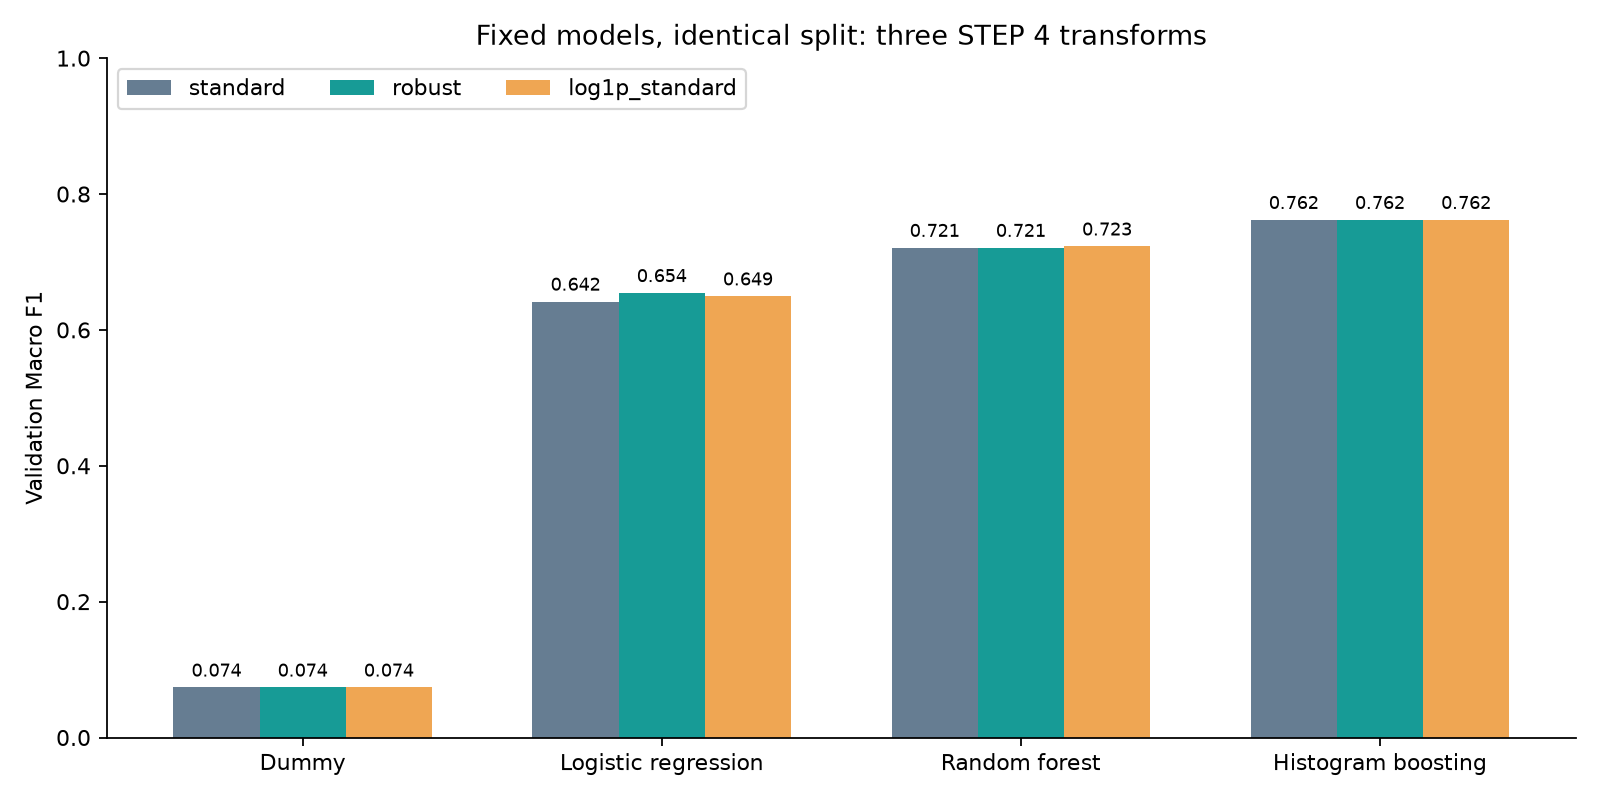

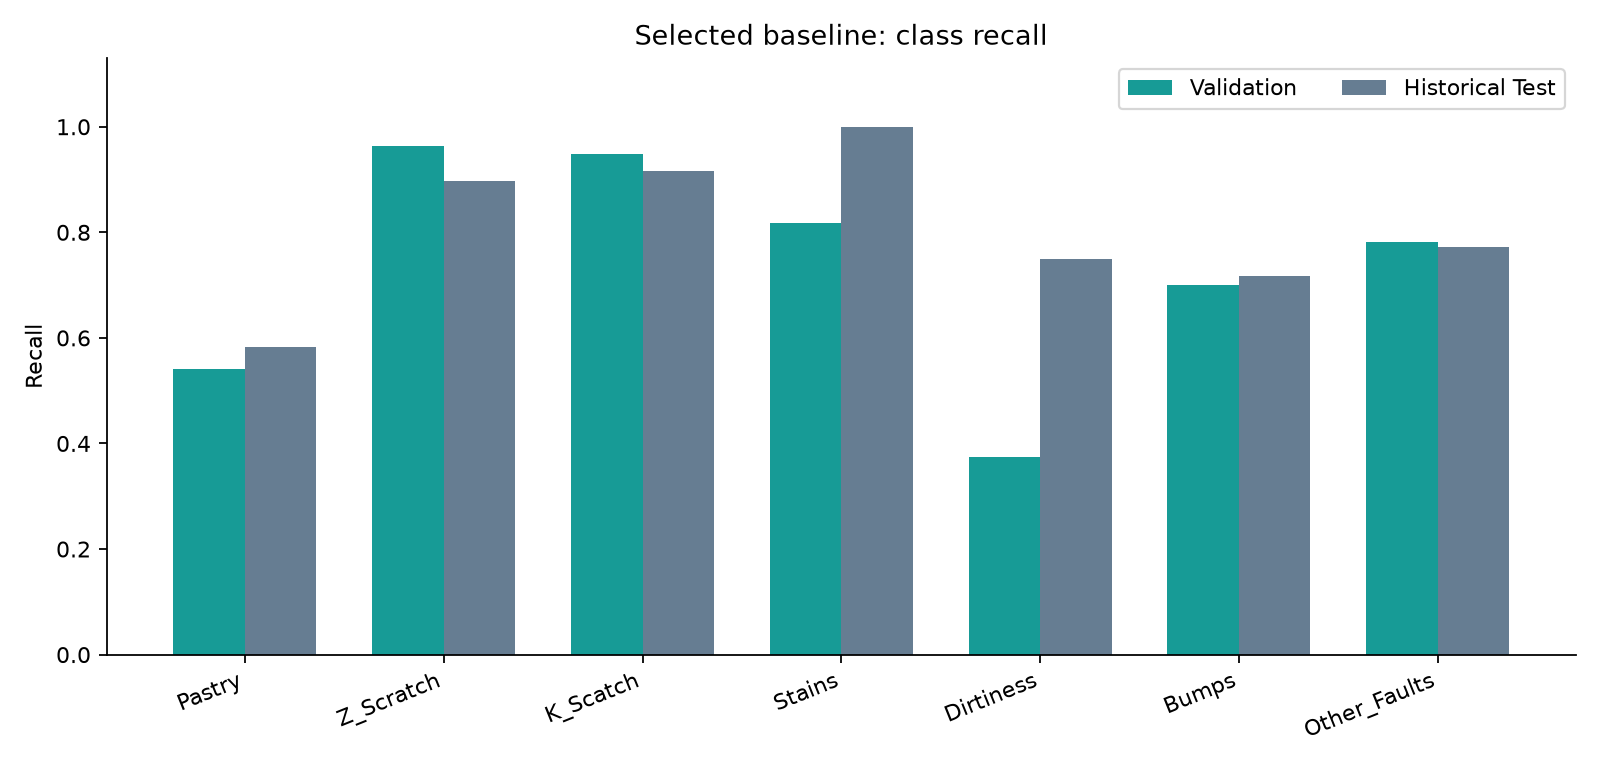

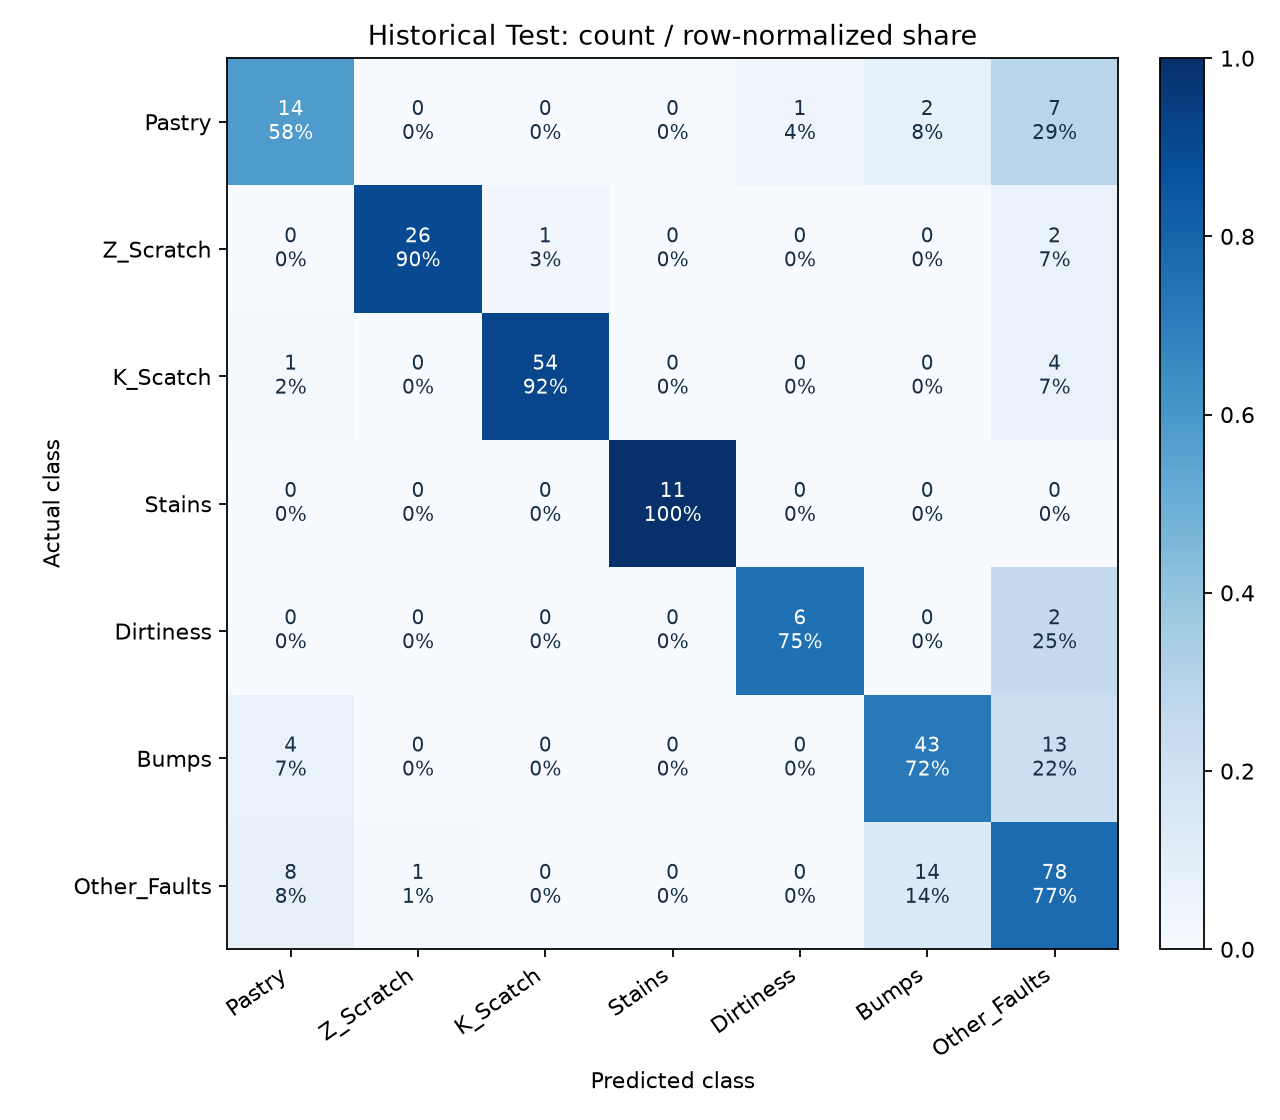

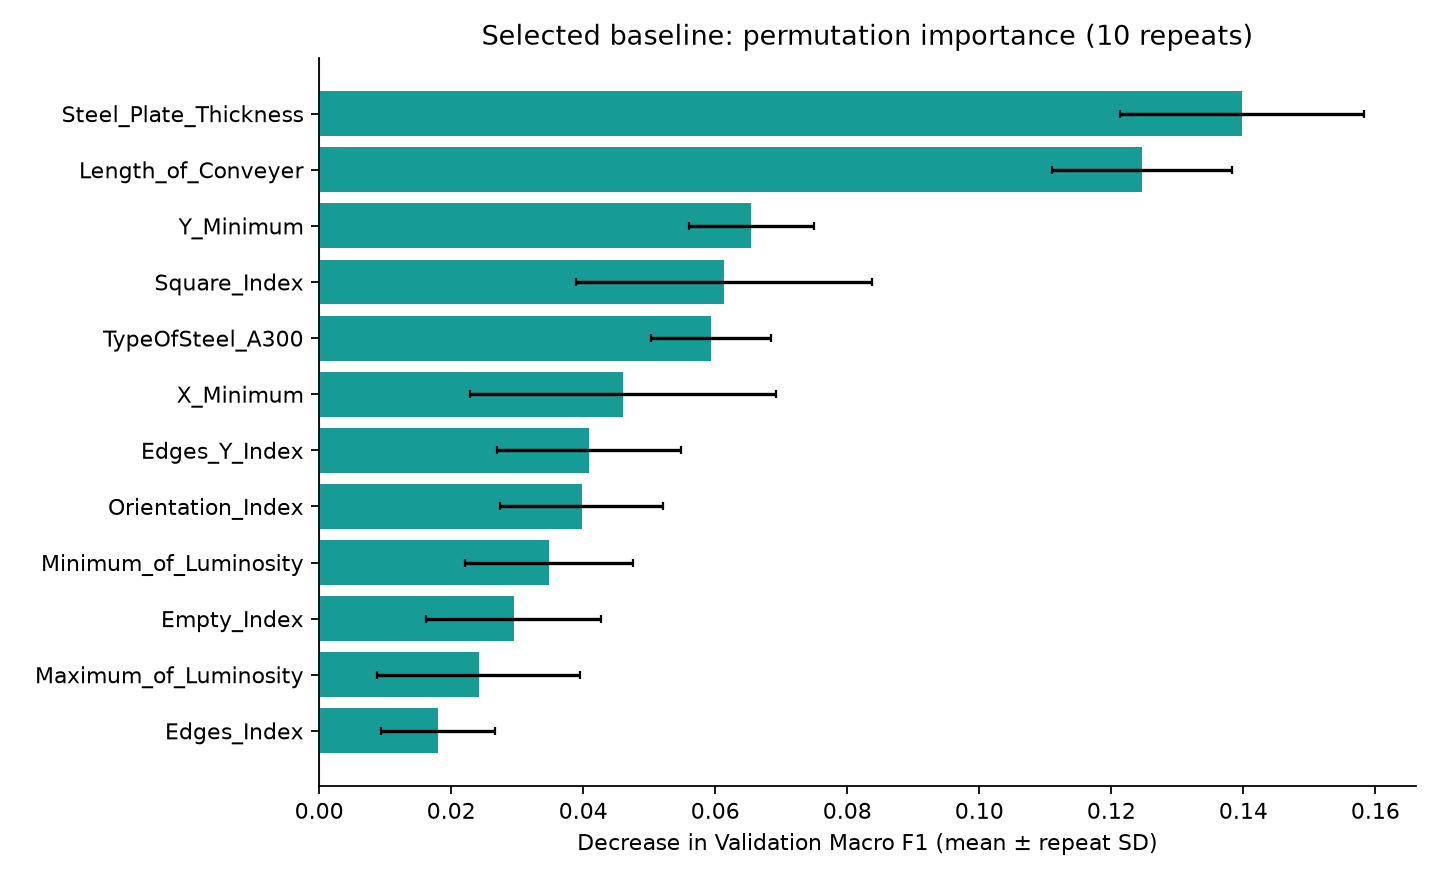

In [18]:
figures=make_figures(comparison,effects,data,valid_predictions,test_class_metrics,importance)
for path in figures:
    display(Image(filename=str(path)))

In [19]:
def format_table(frame,percent_cols=(),decimals=4):
    f=frame.copy()
    for c in f:
        if c in percent_cols:f[c]=f[c].map(lambda v:f'{v:.2%}')
        elif pd.api.types.is_float_dtype(f[c]):f[c]=f[c].map(lambda v:f'{v:.{decimals}f}')
    return f.to_html(index=False,escape=True,border=0,classes='data-table')


def write_report(data,table,effects,sensitivity,group_cv,result,test_report,confusions,importance,figures,warnings_seen):
    selected=table.iloc[0];group_mean=group_cv.macro_f1.mean();group_std=group_cv.macro_f1.std()
    pct=lambda v:f'{v:.2%}'
    view=table[['strategy','model','valid_accuracy','valid_macro_f1','valid_balanced_accuracy','cv_macro_f1_mean','cv_macro_f1_std','train_macro_f1','macro_f1_gap']]
    winner_effect=effects.loc[effects.model.eq(selected.model)&effects.strategy.ne('standard')]
    effect_text=' · '.join(f"{r.strategy}: Macro F1 차이 {r.delta_valid_macro_f1:+.4f}, 예측 변경 {int(r.prediction_disagreements_vs_standard)}건" for r in winner_effect.itertuples())
    lr_effect=effects.loc[effects.model.eq('LogisticRegression')&effects.strategy.eq('robust')].iloc[0]
    empirical_text=f"선정 모델의 두 대안은 기본 표준화와 다음 차이를 보였습니다: {effect_text}. 로지스틱 회귀의 RobustScaler는 Accuracy {lr_effect.delta_valid_accuracy*100:+.2f}%p, Macro F1 {lr_effect.delta_valid_macro_f1:+.4f} 변화가 있었습니다. 전처리의 효과가 모델마다 달랐으므로 변환 자체를 성능 향상으로 일반화하지 않았습니다."

    imgs=[]
    for p in figures:
        b=base64.b64encode(p.read_bytes()).decode();imgs.append(f'<img src="data:image/png;base64,{b}" alt="{html.escape(p.stem)}">')
    current=datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
    content=f'''<header><div class="eyebrow">STEEL PLATES FAULTS · STEP 5</div><h1>이상치 심화전처리 기반<br>Baseline 모델 구축</h1><p class="lead">STEP 4의 1,941건·27개 입력과 고정 분할을 보존하고, 세 가지 전처리 × 네 가지 고정 모델을 비교했습니다.</p><div class="date">실제 실행 결과 · {current}</div></header>
    <section><h2>선정 결과</h2><div class="cards"><div><small>선정 전처리 / 모델</small><b>{selected.strategy}<br>{selected.model}</b></div><div><small>Validation Macro F1</small><b>{selected.valid_macro_f1:.4f}</b><span>Accuracy {pct(selected.valid_accuracy)}</span></div><div><small>기존 Test 참고 성능</small><b>{pct(result['accuracy'])}</b><span>{result['correct']}/{result['total']} 정분류 · Macro F1 {result['macro_f1']:.4f}</span></div></div><p>1차 기준은 Validation Macro F1, 동률일 때 Balanced Accuracy, 기존 표준화 우선순위, 모델명 순서입니다. 선택 기록을 먼저 저장한 뒤 선정 모델만 Test에서 평가했습니다. 학습은 Train 1,358건으로 유지했습니다.</p><aside>같은 Test의 성능이 이전 작업에서 이미 공개되었습니다. 이번 Test 결과는 <strong>기존 Test에 대한 참고 평가</strong>이며, 새로운 독립 검증 성능이나 향상 보장으로 해석할 수 없습니다. 추가적인 최종 검증에는 별도 생산 배치·신규 관측 데이터가 필요합니다.</aside></section>
    <section><h2>1. 입력과 STEP 4 재현 검증</h2><p>직접 기준 자료는 <code>{SOURCE_NOTEBOOK}</code>입니다. 첨부 노트북의 실행 코드를 추출해 재실행하고, 원본 NNA와 변수명 파일을 사용했습니다. 원본 노트북은 보존했고, 스크립트 실행용 폴더 경로 조정과 future import 이동만 적용했습니다. 첨부 노트북의 저장 출력은 CSV 입력을 사용했지만 이번 실행은 NNA 입력을 사용하므로 파일 해시는 다릅니다. 행 수·변수·분할·이상치 집계가 동일하게 재현되는지 검증했습니다.</p>{format_table(data['counts'].reset_index())}<p>전체 1,941건, 입력 27개, 완전 입력 중복 0건. Train/Valid/Test=1,358/291/292, seed=42, 계층 분할입니다. CSV는 <code>float_precision='round_trip'</code>으로 읽어 각 전처리의 실제 변환값과 <strong>9개 행렬의 모든 값을 정확하게 대조</strong>했습니다. 열 순서·정답 정렬·강종 이진값 보존, 결측·무한값·분할 간 동일 입력 중복 0건, Train 통계로만 적합된 중앙값·평균·분산·IQR도 확인했습니다.</p>{format_table(data['checks'])}</section>
    <section><h2>2. 이상치에 대한 결정과 전처리 비교</h2><table><thead><tr><th>전처리</th><th>실제 처리</th></tr></thead><tbody><tr><td>standard</td><td>연속형 25열: Train 중앙값 대체 → StandardScaler. 강종 2열 유지.</td></tr><tr><td>robust</td><td>연속형 25열: Train 중앙값 대체 → RobustScaler(25%, 75%). 강종 2열 유지.</td></tr><tr><td>log1p_standard</td><td>면적·X둘레·Y둘레·밝기합 4열만 중앙값 대체 → log1p → 표준화. 나머지 연속형 21열은 중앙값 대체 → 표준화. 강종 2열 유지.</td></tr></tbody></table><p>StandardScaler는 (x−평균)/표준편차, RobustScaler는 (x−중앙값)/IQR입니다. 로그는 log(1+x)이며 이미 로그 파생된 변수에는 재적용하지 않았습니다. 어느 방법도 값 상한을 자르거나 표본·변수를 제거하지 않습니다. 이상치 플래그와 행 번호는 모델 입력으로 추가하지 않았습니다.</p><p>Train 면적 IQR 후보는 279건, 밝기합 281건, X둘레 227건입니다. 면적 후보를 일괄 삭제하면 K_Scatch 273건 중 231건(84.62%)이 사라질 수 있어 원본을 유지했습니다. IQR/MAD/IsolationForest 결과는 검토용입니다. 산술 관계 검토 대상인 원본 519·592행도 자동 수정하지 않았습니다.</p>{format_table(data['suspects'])}<p>평균 밝기=밝기합/면적이라는 정의가 같은 영역에 적용된다는 가정에서 최소 밝기보다 낮아지는 사례입니다. 원자료 확인이 필요한 의심이며 확정 오류나 오표기로 단정하지 않습니다. 이 데이터는 수정 없이 학습·평가에 유지했습니다.</p></section>
    <section><h2>3. 공정한 Baseline 실험 설계</h2><p>더미 다수 클래스, 다항 로지스틱 회귀, 랜덤포레스트, 히스토그램 부스팅의 4개 모델을 각각 세 전처리로 학습했습니다. 로지스틱 회귀 C=1·최대 5,000회, 랜덤포레스트 300개 트리·sqrt 특성 선택, 부스팅 100회·학습률 0.1·최대 리프 31·조기종료 해제입니다. 하이퍼파라미터 탐색, 클래스 가중치, SMOTE, 특성 추가·제거, 임계값 조정은 적용하지 않았습니다. 출력 확률은 보정하지 않은 모델 확률입니다.</p><p>Train 내부 5-fold 계층 교차검증은 12개 조건에 동일한 fold를 사용했습니다. 각 fold에서 원시 입력에 전처리·모델 전체를 새로 적합했습니다. 전체 Train에서 미리 표준화한 CSV를 교차검증에 넣지 않았습니다. 평균±표준편차는 분할 변동 진단이며 신뢰구간이 아닙니다. 전처리·모델 선택은 고정 Validation 성능으로 수행했습니다.</p>{format_table(view, ['valid_accuracy','valid_balanced_accuracy'])}{imgs[0]}<p>학습–검증 격차는 훈련 데이터에 대한 낙관적 적합 정도를 보는 진단입니다. 정확도만으로는 다수 클래스 효과를 분리하기 어려워 각 클래스를 같은 비중으로 평균한 Macro F1을 우선했습니다. Balanced Accuracy는 클래스별 Recall의 평균입니다.</p></section>
    <section><h2>4. 이상치 대응 전처리의 실제 효과</h2><p>아래 값은 <strong>같은 모델의 standard 대비</strong> 차이입니다. delta는 비율 단위이므로 0.01은 1%p입니다. 새로 맞힌 건수와 새로 틀린 건수를 함께 제시했습니다. 로그 변환이 왜도를 줄였다는 사실만으로 분류 성능 향상을 주장하지 않았습니다.</p>{format_table(effects)}<p><strong>실측 해석:</strong> {empirical_text}</p><p>트리 모델은 대체로 단조 변환에 둔감하지만 히스토그램 경계·부동소수점·무작위 분할 등의 영향으로 예측이 완전히 일치하지 않을 수 있습니다. 이 단일 Validation 결과로 특정 변환의 우월성이 입증된 것은 아닙니다.</p></section>
    <section><h2>5. 유형별 성능과 기존 Test 참고 평가</h2><p>선정 기준선의 기존 Test Accuracy는 <strong>{pct(result['accuracy'])}</strong>, Macro F1 <strong>{result['macro_f1']:.4f}</strong>, Balanced Accuracy {pct(result['balanced_accuracy'])}, Weighted F1 {result['weighted_f1']:.4f}입니다. Accuracy의 명목상 Wilson 95% 구간은 {pct(result['accuracy_wilson95_low'])}–{pct(result['accuracy_wilson95_high'])}입니다. 이 구간은 한 고정 모델의 이항 표본 오차만 표현하며, 모델 선택·유사 관측치·Test의 이전 공개에 따른 불확실성을 반영하지 않습니다.</p>{format_table(test_report)}{imgs[1]}{imgs[2]}<p>소수 클래스의 평가 표본은 매우 작습니다. Dirtiness는 Test 8건, Stains는 11건이므로 한 건 차이만으로 Recall이 각각 12.5%p와 약 9.1%p 변합니다. 소수 유형의 높은 수치도 안정된 성능으로 단정하기 어렵습니다.</p><h3>주요 오분류 방향</h3>{format_table(confusions.head(12))}<p>오분류 원본 행 번호·정답·예측·모델 확률은 <code>16_test_errors.csv</code>에 제공합니다. 이 목록은 오류 해석용이며 이번 실행에서 재학습·전처리 선택에 사용하지 않았습니다.</p></section>
    <section><h2>6. 유사 관측치와 해석의 한계</h2><p>STEP 4의 유사 후보 35쌍 중 분할 간 후보는 12쌍입니다. 확정 중복이 아니므로 삭제하지 않았습니다. Train과 유사 후보로 연결된 Valid 행을 제외한 아래 평가를 선택 후 민감도 진단으로 제시했습니다.</p>{format_table(sensitivity)}<p>선정 모델의 추가 Train 그룹 교차검증은 Train–Train 후보 연결 성분을 같은 fold에 묶었습니다. Macro F1 평균±SD는 <strong>{group_mean:.4f}±{group_std:.4f}</strong>입니다. 일반 Train CV {selected.cv_macro_f1_mean:.4f}±{selected.cv_macro_f1_std:.4f}와는 fold 구성 자체가 달라 순수한 누수 효과의 크기로 해석할 수 없습니다. 후보 관계는 실제 코일·배치 ID를 대신하지 못합니다. 시간·생산 배치 정보 부재로 현장 일반화는 검증되지 않았습니다.</p><h3>Validation에서의 변수 중요도</h3>{imgs[3]}<p>변수 한 개를 섞었을 때 Macro F1 감소를 10회 계산했습니다. 오차 막대는 반복 표준편차이며 신뢰구간이 아닙니다. 상관·파생변수가 서로 정보를 대신하므로 중요도는 인과적 영향이나 변수 제거 기준으로 사용할 수 없습니다.</p></section>
    <section><h2>7. 재현·인수인계</h2><p>전체 ZIP을 풀고 프로젝트 폴더에서 <code>pip install -r requirements.txt</code> 후 노트북을 위에서부터 실행하거나 <code>python baseline_step5_advanced.py</code>를 실행하면 됩니다. 실행완료 노트북, 원본 STEP 4, 원시 데이터, 3개 전처리의 Train/Valid/Test CSV, 모든 비교표·fold 정보·예측·오분류, 선정 모델, 환경·원본 해시·선정 기록을 포함합니다. 선정 모델은 27개 원시 입력 DataFrame을 받아 전처리부터 예측까지 수행합니다.</p><p><code>predict_new.py --input new_features.csv --output predictions.csv</code>로 새 입력을 예측할 수 있습니다. 저장 모델은 로컬 재로딩 후 Valid 예측의 일치를 확인했습니다. 원본 자료와 첨부 노트북의 SHA-256 유지도 마지막에 재검증했습니다. 모델 적합 경고 {len(warnings_seen)}건, 수렴 경고 0건입니다. 보고서·그래프는 실제 실행 결과에서 생성했습니다.</p><aside>다음 단계는 기존 Test를 반복 최적화하는 것이 아니라, 선정 기준선을 고정하고 개발 데이터 안에서 튜닝·가중치 실험을 분리해 수행한 뒤 새로운 배치로 평가하는 것입니다. 이번 결과는 STEP 5의 재현 가능한 기준선입니다.</aside></section>'''
    css='''*{box-sizing:border-box}body{margin:0;background:#eef2f5;color:#213448;font:15px/1.72 -apple-system,BlinkMacSystemFont,"Noto Sans KR","Malgun Gothic",sans-serif}main{max-width:1180px;margin:auto;padding:38px 32px 80px}header{background:#102f47;color:white;padding:44px 46px;border-radius:16px;margin-bottom:28px}.eyebrow{font-size:12px;letter-spacing:2px;color:#7ed9ce}h1{font-size:36px;line-height:1.3;margin:14px 0 18px}.lead{font-size:17px;max-width:880px;color:#dae6ef}.date{font-size:12px;color:#9fb8c9}section{background:white;padding:28px 32px;margin:20px 0;border-radius:12px;overflow-x:auto}h2{font-size:23px;line-height:1.4;color:#133c55;margin:0 0 18px}h3{font-size:17px}p{margin:14px 0}table{border-collapse:collapse;width:100%;font-size:12px;line-height:1.5;margin:18px 0}th{background:#eaf3f5;color:#163d52;text-align:left}th,td{padding:9px 10px;border-bottom:1px solid #dde6ec;overflow-wrap:anywhere}tbody tr:nth-child(even){background:#f7fafb}img{display:block;max-width:100%;height:auto;margin:24px auto}aside{border-left:4px solid #e7ad50;background:#fff6e6;padding:16px 20px;margin:20px 0;font-size:14px}code{background:#edf2f6;padding:2px 5px;border-radius:4px;font-size:12px;overflow-wrap:anywhere}.cards{display:grid;grid-template-columns:1.2fr 1fr 1fr;gap:16px;margin:20px 0}.cards>div{background:#edf6f5;border-top:3px solid #1c948b;padding:20px;border-radius:6px}.cards small,.cards span{display:block;font-size:12px}.cards b{display:block;font-size:22px;line-height:1.4;margin:10px 0;color:#105a60}@media(max-width:760px){main{padding:12px}header,section{padding:22px}.cards{grid-template-columns:1fr}h1{font-size:28px}}@media print{body{background:white}main{padding:0}section{break-inside:avoid}header{print-color-adjust:exact}}'''
    path=OUT/'STEP5_이상치심화전처리_Baseline_실측보고서.html'
    path.write_text(f'<!doctype html><html lang="ko"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>STEP5 이상치 심화전처리 Baseline 실측보고서</title><style>{css}</style><body><main>{content}</main></body></html>',encoding='utf-8')
    write_json(OUT/'execution_manifest.json',{'completed_utc':current,'selected':selected.candidate,
        'conditions':len(table),'train_cv_fits':60,'group_cv_fits':5,'selection_metric':'Valid macro F1',
        'source_attachment':SOURCE_NOTEBOOK,'source_fingerprints':data['fingerprints'],
        'source_files_unchanged':all(digest(ROOT/k)==v for k,v in data['fingerprints'].items()),
        'warning_count':len(warnings_seen),'warnings':warnings_seen,
        'test_reference_metrics':result,'package_versions':{'python':platform.python_version(),
            'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'joblib':joblib.__version__}})
    assert all(digest(ROOT/k)==v for k,v in data['fingerprints'].items())
    return path

In [20]:
report_path=write_report(data,comparison,effects,valid_sensitivity,group_cv,test_result,test_class_metrics,
                         test_confusions,importance,figures,cv_warnings+fit_warnings)
print('보고서:',report_path.name)
print('모델 적합 경고:',len(cv_warnings+fit_warnings))
assert len(comparison)==12
assert len(pd.read_csv(OUT/'04_train_cv_detail.csv'))==60
assert all(digest(ROOT/k)==v for k,v in data['fingerprints'].items())
print('12개 조건 / 60회 Train CV / 5회 그룹 CV / 원본 해시 유지 검증 통과')

보고서: STEP5_이상치심화전처리_Baseline_실측보고서.html
모델 적합 경고: 0
12개 조건 / 60회 Train CV / 5회 그룹 CV / 원본 해시 유지 검증 통과


## 9. 결과에 따른 결론과 STEP 6 연결

아래 셀은 실행된 점수에서 결론을 작성합니다. Accuracy 목표를 맞추기 위해 Test에 따라 추가 탐색하지 않습니다. 다음 단계는 이 기준선을 고정한 상태에서 개발 데이터 내부 튜닝·가중치 실험을 분리하고, 새로운 생산 배치로 최종 검증하는 것입니다.

**저장 산출물:** 전체 비교표·클래스 지표·모든 Valid 예측·fold 정보, 전처리 효과, 유사 후보 민감도, 중요도, 선정 모델의 Test 참고 지표·확률·오분류, 원시 입력 Pipeline, 실측 HTML 보고서, 모델 카드·실행 이력.

In [21]:
display(HTML(f"""<div style='padding:20px;border-left:5px solid #179b96;background:#edf7f5'>
<b>선정 기준선: {selected.strategy} + {selected.model}</b><br>
Validation Accuracy {selected.valid_accuracy:.2%} / Macro F1 {selected.valid_macro_f1:.4f}<br>
기존 Test 참고 Accuracy {test_result['accuracy']:.2%} ({test_result['correct']}/{test_result['total']}) / Macro F1 {test_result['macro_f1']:.4f}<br>
원본 1,941건·27개 입력 보존, 이상치 임의 삭제·수정 없음. 동일 Test의 과거 공개로 새로운 독립 성능 검증에는 별도 데이터가 필요합니다.
</div>"""))

## 10. 전처리·모델별 7개 클래스 Recall 전체 비교

아래 표는 같은 Valid 291건에서 계산한 12개 조건의 클래스별 Recall입니다. 선정 모델은 Dirtiness 3/8건(37.5%), Pastry 14/24건(58.3%)을 맞혔습니다. Dirtiness는 기존 Test에서 6/8건으로 달라져, 작은 표본과 분할 변동이 성능 해석에 큰 영향을 줍니다. 강건·로그 전처리는 선정 부스팅의 이 약점을 개선하지 못했습니다.

실측 CSV를 비교표로 정리하고 동일 표를 HTML 보고서에도 추가합니다. 추가 모델 학습이나 Test 재평가는 수행하지 않습니다.

In [22]:
def add_class_recall_comparison(comparison, report_path):
    reports=pd.read_csv(OUT/'07_validation_class_metrics.csv')
    recall=reports.pivot(index='candidate',columns='class',values='recall').reindex(
        index=comparison.candidate,columns=LABELS)
    save_csv(recall.rename_axis('candidate'),'18_validation_recall_matrix.csv',index=True)
    selected=recall.iloc[0]
    weaknesses=' · '.join(f'{c} {v:.2%}' for c,v in selected.nsmallest(2).items())
    block='<section id="valid-recall-comparison"><h2>4-B. Validation 유형별 재현율 비교</h2>'
    block+='<p>12개 조건에 동일한 7개 유형의 Recall을 비교했습니다. 선정 모델의 낮은 두 유형은 '+weaknesses+'입니다. 전체 정확도와 별도로 후속 개선의 기준으로 삼아야 합니다.</p>'
    block+=format_table(recall.reset_index(),percent_cols=LABELS)
    block+='<p>Valid Dirtiness 8건과 Pastry 24건 중 각각 3건·14건을 맞혔습니다. Dirtiness는 기존 Test에서 6/8건으로 달라져 작은 표본과 분할 변동에 주의해야 합니다. 이 비교를 근거로 Test 확인 후 모델을 변경하지 않았습니다.</p></section>'
    path=Path(report_path);text=path.read_text(encoding='utf-8')
    if 'id="valid-recall-comparison"' not in text:
        text=text.replace('<section><h2>5. 유형별 성능과 기존 Test 참고 평가</h2>',
                          block+'<section><h2>5. 유형별 성능과 기존 Test 참고 평가</h2>')
        path.write_text(text,encoding='utf-8')
    return recall

In [23]:
valid_recall_matrix=add_class_recall_comparison(comparison,report_path)
display(valid_recall_matrix.round(4))
print('7개 유형 Recall 비교표 및 보고서 반영 완료')

class,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
candidate,,,,,,,
standard__HistGradientBoosting,0.5417,0.9643,0.9492,0.8182,0.375,0.7000,0.7822
robust__HistGradientBoosting,0.5417,0.9643,0.9492,0.8182,0.375,0.7000,0.7822
log1p_standard__HistGradientBoosting,0.5417,0.9643,0.9492,0.8182,0.375,0.7000,0.7822
log1p_standard__RandomForest,0.4167,0.7857,0.9153,0.8182,0.375,0.6833,0.8020
standard__RandomForest,0.4167,0.7857,0.9153,0.8182,0.375,0.6667,0.8020
robust__RandomForest,0.4167,0.7857,0.9153,0.8182,0.375,0.6667,0.8020
robust__LogisticRegression,0.4167,0.8214,0.8983,0.8182,0.250,0.5667,0.6931
log1p_standard__LogisticRegression,0.4167,0.8214,0.8983,0.8182,0.250,0.5500,0.6832
standard__LogisticRegression,0.4167,0.8214,0.8983,0.8182,0.250,0.5333,0.6733


7개 유형 Recall 비교표 및 보고서 반영 완료
